In [231]:
import math 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal
from scipy.ndimage import gaussian_filter1d

from plot_helpers import plot_signal, plot_emg_vs_joystick, plot_frequencies

In [232]:
def causal_bandpass(x, fs, low=70, high=294, order=4):
    b, a = signal.butter(order, [low, high], btype="bandpass", fs=fs)
    return signal.lfilter(b, a, x)

def rolling_rms(x, fs, window_ms=50):
    w = max(1, int(fs * window_ms / 1000))
    x2 = np.asarray(x) ** 2
    kernel = np.ones(w) / w
    return np.sqrt(np.convolve(x2, kernel, mode="same"))

def preprocess_emg_rms(df, fs, window_ms=50):
    df = df.copy()

    df["emg_ext_bp"] = causal_bandpass(df["emg_ext"].values, fs)
    df["emg_flex_bp"] = causal_bandpass(df["emg_flex"].values, fs)

    df["ext_rms"] = rolling_rms(df["emg_ext_bp"].values, fs, window_ms)
    df["flex_rms"] = rolling_rms(df["emg_flex_bp"].values, fs, window_ms)

    return df

def preprocess_emg_butter(df, fs, low_pass_hz=1):
    df = df.copy()

    df["emg_ext_bp"]  = causal_bandpass(df["emg_ext"].values, fs)
    df["emg_flex_bp"] = causal_bandpass(df["emg_flex"].values, fs)

    df["emg_ext_rect"]  = np.abs(df["emg_ext_bp"])
    df["emg_flex_rect"] = np.abs(df["emg_flex_bp"])

    b_lp, a_lp = signal.butter(2, low_pass_hz, btype="lowpass", fs=fs)
    df["ext_env"]  = signal.filtfilt(b_lp, a_lp, df["emg_ext_rect"])
    df["flex_env"] = signal.filtfilt(b_lp, a_lp, df["emg_flex_rect"])

    return df

def smooth_signal(x, fs, lp_hz=5):
    b, a = signal.butter(2, lp_hz, btype="lowpass", fs=fs)
    return signal.filtfilt(b, a, x)


def gaussian_smooth_target(x, fs, sigma_ms=150):
    sigma_samples = sigma_ms / 1000 * fs
    return gaussian_filter1d(
        x.astype(float),
        sigma=sigma_samples,
        mode="nearest"
    )

In [233]:
df = pd.read_csv("data_for_cleaning_3.csv")

df["t"] = df["t_micros"] * 1e-6

df["emg_ext"] -= df["emg_ext"].mean()
df["emg_flex"] -= df["emg_flex"].mean()


 
df["y_top"] = gaussian_smooth_target(-df["y_top"] + 500, fs, 150)
df["y_bottom"] = gaussian_smooth_target(-df["y_bottom"] + 550, fs, 150)
df["joy"] = df["y_top"] + df["y_bottom"]

df.dropna(inplace=True)

print(len(df))
df.head()

14858


,pc_time,t_micros,y_top,y_bottom,emg_ext,emg_flex,command,block_id,t,joy
0,1.779745e+09,8,-19.987158,13.053972,8.971194,-56.642415,rest,1,0.000008,-6.933186
1,1.779745e+09,1312,-19.987038,13.055046,9.971194,3.357585,rest,1,0.001312,-6.931992
2,1.779745e+09,2696,-19.986919,13.056134,6.971194,76.357585,rest,1,0.002696,-6.930785
3,1.779745e+09,4064,-19.986800,13.057234,0.971194,126.357585,rest,1,0.004064,-6.929566
4,1.779745e+09,5456,-19.986681,13.058349,-6.028806,146.357585,rest,1,0.005456,-6.928333


In [234]:
df = preprocess_emg_rms(df, fs, window_ms=200)
df = preprocess_emg_butter(df, fs, low_pass_hz=1)

gain_flex = df["ext_env"].std() / df["flex_env"].std()
df["activity"] = (df["ext_rms"]-df["ext_rms"].mean()) - (df["flex_rms"]-df["flex_rms"].mean())*gain_flex

df = df.iloc[300:]

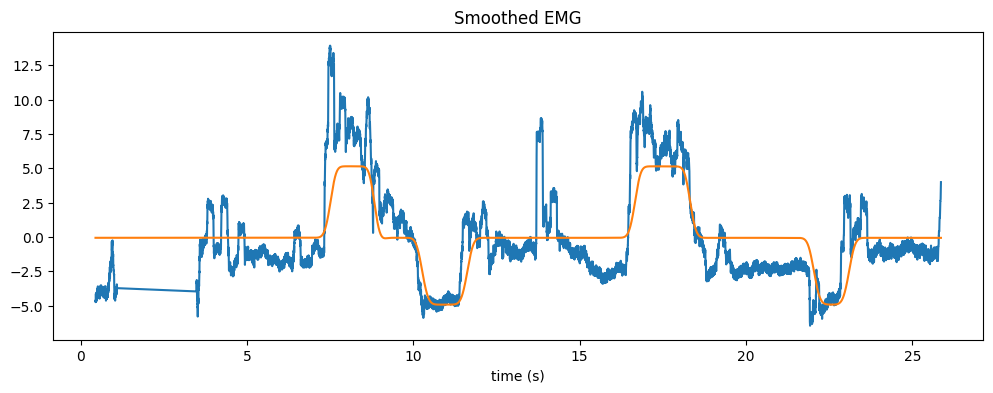

In [235]:
plot_emg_vs_joystick(df["t"], df["activity"], df["joy"]/100)

In [236]:
dt = np.median(np.diff(df["t"].values))

df["joy_top_vel"] = np.gradient(df["y_top"].values, dt)
df["joy_bottom_vel"] = np.gradient(df["y_bottom"].values, dt)

df["joy_top_abs_vel"] = np.abs(df["joy_top_vel"])
df["joy_bottom_abs_vel"] = np.abs(df["joy_bottom_vel"])

In [237]:
def get_blocks(df):
    blocks = []
    for block_id, g in df.groupby("block_id"):
        blocks.append({
            "block_id": block_id,
            "command": g["command"].iloc[0],
            "start_t": g["t"].iloc[0],
            "end_t": g["t"].iloc[-1],
            "data": g.copy()
        })
    return blocks

def plot_blocks_grid(
    df,
    signal_cols,
    block_ids=None,
    ncols=3,
    max_blocks=18,
    normalize=True,
):
    if block_ids is None:
        block_ids = sorted(df["block_id"].unique())[:max_blocks]
    else:
        block_ids = block_ids[:max_blocks]

    nrows = math.ceil(len(block_ids) / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 3*nrows), sharex=False)
    axes = np.array(axes).reshape(-1)

    for ax, block_id in zip(axes, block_ids):
        g = df[df["block_id"] == block_id].copy()
        command = g["command"].iloc[0]

        t = g["t"] - g["t"].iloc[0]

        for col in signal_cols:
            y = g[col].values.astype(float)

            if normalize:
                sd = np.std(y)
                if sd > 0:
                    y = (y - np.mean(y)) / sd

            ax.plot(t, y, label=col)

        ax.set_title(f"block {block_id} | {command}")
        ax.set_xlabel("t relativo")
        ax.grid(True)
        ax.legend(fontsize=8)

    for ax in axes[len(block_ids):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    
blocks = get_blocks(df)

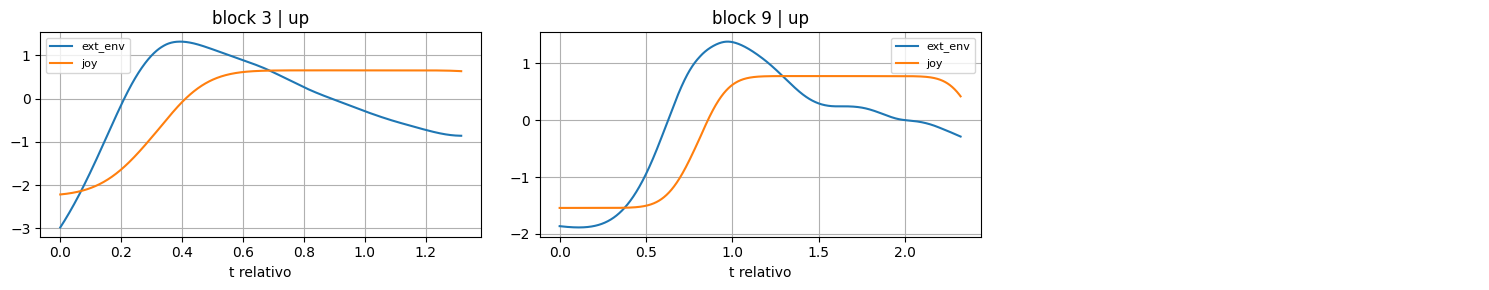

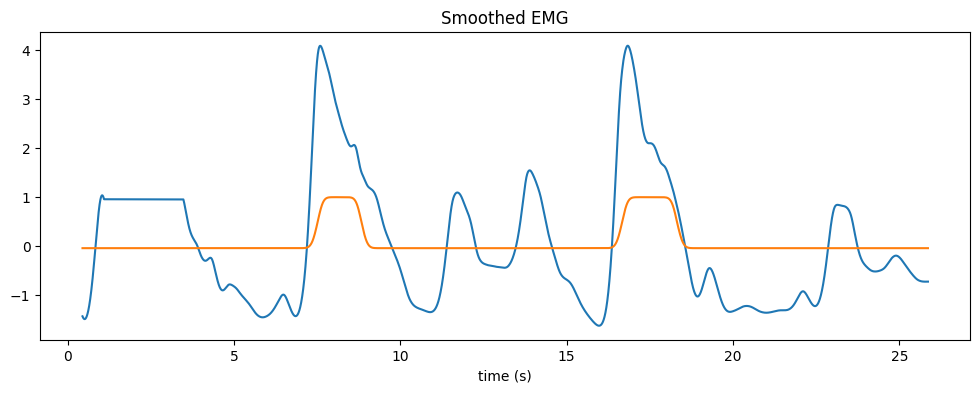

In [240]:
plot_blocks_grid(df, signal_cols=("ext_env", "joy"), block_ids=list(df.loc[df["command"].eq("up"), "block_id"].unique()))
plot_emg_vs_joystick(df["t"], df["ext_env"]-df["ext_env"].mean(), df["y_top"]/500)

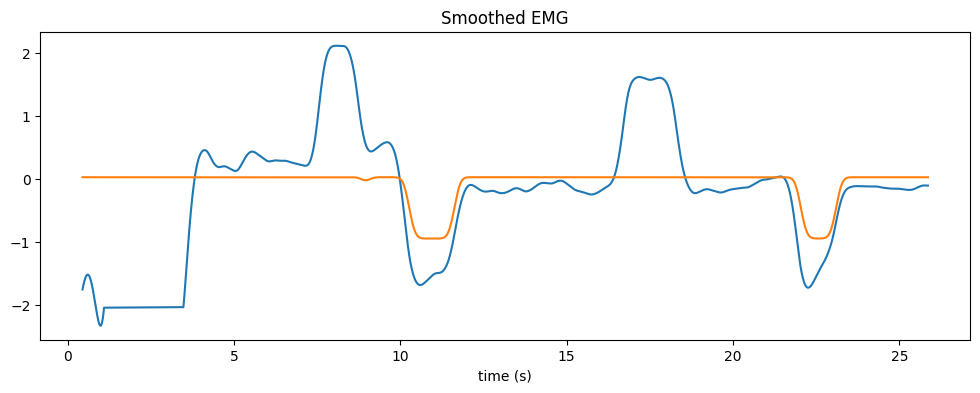

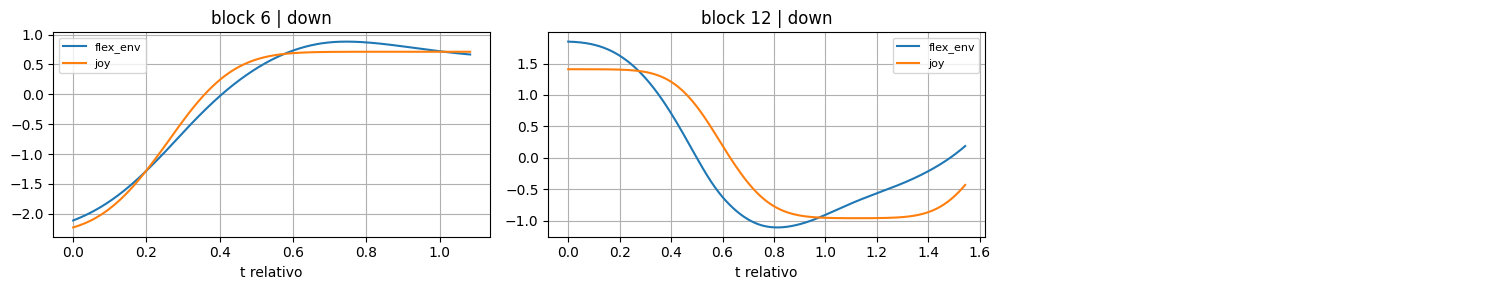

In [239]:
df["flex_env"] = -df["flex_env"]
plot_emg_vs_joystick(df["t"], df["flex_env"]-df["flex_env"].mean(), df["y_bottom"]/500)
plot_blocks_grid(df, signal_cols=("flex_env", "joy"), block_ids=list(df.loc[df["command"].eq("down"), "block_id"].unique()))

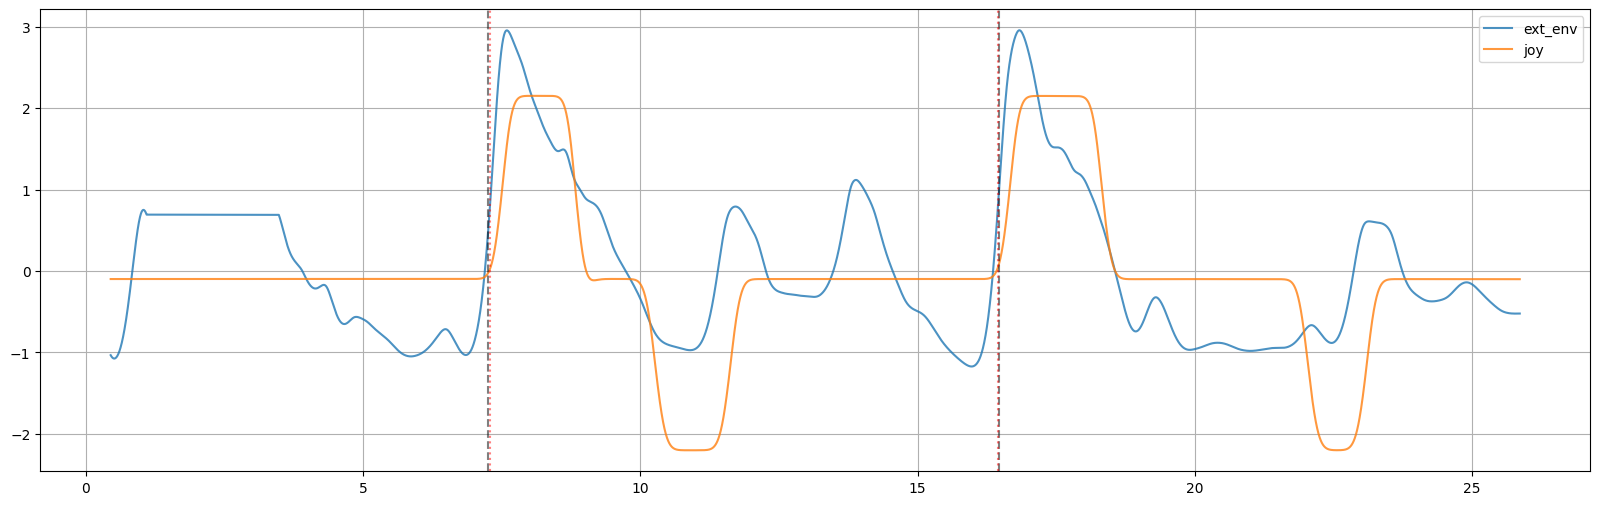

In [243]:
def first_sustained_crossing_from_mask(t, mask, sustain_ms, fs):
    sustain_n = max(1, int(fs * sustain_ms / 1000))
    mask = np.asarray(mask)

    for i in range(len(mask) - sustain_n + 1):
        if mask[i:i+sustain_n].all():
            return t.iloc[i], i

    return np.nan, None


def sustained_crossings_from_mask(t, mask, sustain_ms, fs):
    sustain_n = max(1, int(fs * sustain_ms / 1000))
    mask = np.asarray(mask)

    crossings = []
    i = 0

    while i <= len(mask) - sustain_n:
        if mask[i:i+sustain_n].all():
            crossings.append((t.iloc[i], i))

            # salteamos hasta que vuelva a estar debajo del threshold
            while i < len(mask) and mask[i]:
                i += 1
        else:
            i += 1

    return crossings


def choose_emg_onset_near_joy(emg_crossings, t_joy, prefer_before=True):
    if len(emg_crossings) == 0 or np.isnan(t_joy):
        return np.nan, None

    if prefer_before:
        before = [(t, i) for t, i in emg_crossings if t <= t_joy]

        if len(before) > 0:
            # último cruce sostenido antes del onset del joystick
            return max(before, key=lambda p: p[0])

    # fallback: cruce más cercano en valor absoluto
    return min(emg_crossings, key=lambda p: abs(p[0] - t_joy))


def detect_onsets_full_signal(
    df,
    fs,
    emg_col,
    joy_col,
    command_filter=("up", "down"),
    k_emg=3,
    k_joy=5,
    min_joy_delta=30,
    sustain_ms=40,
    pre_s=0.8,
    post_s=1.2,
    prefer_emg_before_joy=True,
):
    results = []

    for block_id in sorted(df["block_id"].unique()):
        block = df[df["block_id"] == block_id]
        command = block["command"].iloc[0]

        if command not in command_filter:
            continue

        prev_rest_ids = df.loc[
            (df["block_id"] < block_id) & (df["command"] == "rest"),
            "block_id"
        ]

        if prev_rest_ids.empty:
            continue

        baseline_id = prev_rest_ids.max()
        baseline = df[df["block_id"] == baseline_id]

        t0 = block["t"].iloc[0]
        t1 = block["t"].iloc[-1]

        window = df[
            (df["t"] >= t0 - pre_s) &
            (df["t"] <= t1 + post_s)
        ].copy()

        emg_thr = baseline[emg_col].mean() + k_emg * baseline[emg_col].std()

        joy_base = baseline[joy_col].median()
        joy_noise = baseline[joy_col].std()
        joy_thr = max(min_joy_delta, k_joy * joy_noise)

        emg_mask = window[emg_col] > emg_thr
        joy_disp = np.abs(window[joy_col] - joy_base)
        joy_mask = joy_disp > joy_thr

        t_joy, i_joy = first_sustained_crossing_from_mask(
            window["t"], joy_mask, sustain_ms, fs
        )

        emg_crossings = sustained_crossings_from_mask(
            window["t"], emg_mask, sustain_ms, fs
        )

        t_emg, i_emg = choose_emg_onset_near_joy(
            emg_crossings,
            t_joy,
            prefer_before=prefer_emg_before_joy,
        )

        results.append({
            "block_id": block_id,
            "command": command,
            "baseline_block_id": baseline_id,
            "t_block_start": t0,
            "t_block_end": t1,
            "t_emg_onset": t_emg,
            "t_joy_onset": t_joy,
            "delta_joy_minus_emg": t_joy - t_emg,
            "emg_threshold": emg_thr,
            "joy_baseline": joy_base,
            "joy_noise": joy_noise,
            "joy_threshold": joy_thr,
            "k_emg": k_emg,
            "k_joy": k_joy,
            "min_joy_delta": min_joy_delta,
            "n_emg_candidates": len(emg_crossings),
            "emg_candidates": emg_crossings,
            "emg_col": emg_col,
            "joy_col": joy_col,
        })

    return pd.DataFrame(results)


onsets_ext_full = detect_onsets_full_signal(
    df,
    fs,
    emg_col="ext_env",   
    joy_col="y_top",
    command_filter=("up",),
    k_emg=1.5,
    k_joy=5,
    sustain_ms=30,
    pre_s=0.8,
    post_s=1.2,
)

onsets_flex_full = detect_onsets_full_signal(
    df,
    fs,
    emg_col="flex_env", 
    joy_col="y_bottom",
    command_filter=("down",),
    k_emg=1.5,
    k_joy=5,
    sustain_ms=30,
    pre_s=1.0,
    post_s=1.2,
)

def z(x):
    x = np.asarray(x, dtype=float)
    return (x - np.nanmean(x)) / (np.nanstd(x) + 1e-9)

def plot_full_onsets(df, onsets_list, cols=("ext_env", "flex_env", "y_top", "y_bottom")):
    plt.figure(figsize=(20, 6))

    for col in cols:
        plt.plot(df["t"], z(df[col]), label=col, alpha=0.8)

    for onsets in onsets_list:
        for _, r in onsets.iterrows():
            if not np.isnan(r["t_emg_onset"]):
                plt.axvline(r["t_emg_onset"], linestyle="--", alpha=0.5, color="black")
            if not np.isnan(r["t_joy_onset"]):
                plt.axvline(r["t_joy_onset"], linestyle=":", alpha=0.5, color="red")

    plt.legend()
    plt.grid(True)
    plt.show()

plot_full_onsets(
    df,
    [onsets_ext_full],
    cols=("ext_env", "joy")
)

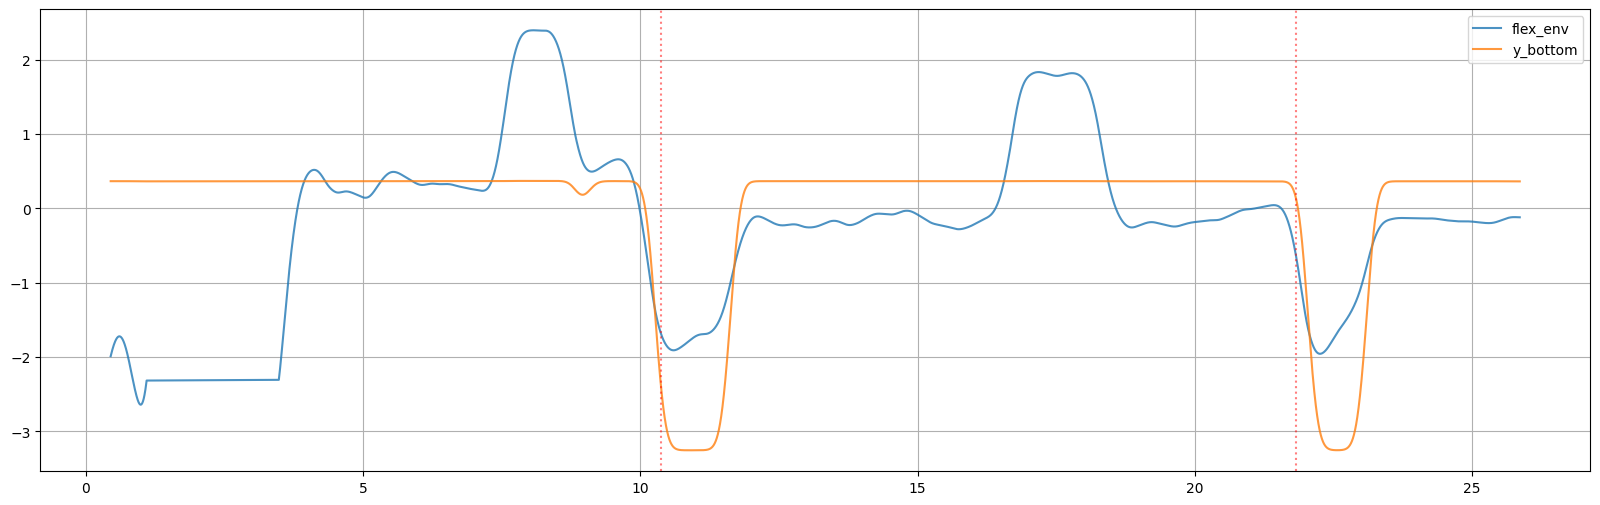

In [245]:
plot_full_onsets(df,[onsets_flex_full],cols=("flex_env", "y_bottom"))

In [246]:
def clean_deltas(onsets_df, col="delta_joy_minus_emg", q_low=0.05, q_high=0.95):
    x = onsets_df[col].dropna()

    lo = x.quantile(q_low)
    hi = x.quantile(q_high)

    clean_df = onsets_df[
        onsets_df[col].between(lo, hi)
    ].copy()

    outliers_df = onsets_df[
        ~onsets_df[col].between(lo, hi)
    ].copy()

    return clean_df, outliers_df, lo, hi
    
def summarize_onset_deltas(
    onsets_df,
    col="delta_joy_minus_emg",
    remove_outliers=True,
    q_low=0.05,
    q_high=0.90,
):
    if remove_outliers:
        clean_df, outliers_df, lo, hi = clean_deltas(onsets_df, col, q_low, q_high)
        x = clean_df[col].dropna()
    else:
        clean_df = onsets_df
        outliers_df = pd.DataFrame()
        lo, hi = np.nan, np.nan
        x = onsets_df[col].dropna()

    summary = {
        "count": len(x),
        "removed_outliers": len(outliers_df),
        "outlier_low": lo,
        "outlier_high": hi,
        "mean": x.mean(),
        "median": x.median(),
        "std": x.std(),
        "min": x.min(),
        "max": x.max(),
        "q10": x.quantile(0.10),
        "q25": x.quantile(0.25),
        "q50": x.quantile(0.50),
        "q75": x.quantile(0.75),
        "q90": x.quantile(0.90),
    }

    return pd.Series(summary)

def plot_delta_histogram(
    onsets_df,
    col="delta_joy_minus_emg",
    bins=20,
    remove_outliers=True,
    q_low=0.05,
    q_high=0.9,
):
    if remove_outliers:
        clean_df, outliers_df, lo, hi = clean_deltas(onsets_df, col, q_low, q_high)
        x = clean_df[col].dropna()
    else:
        x = onsets_df[col].dropna()

    plt.figure(figsize=(8, 4))
    plt.hist(x, bins=bins)

    plt.axvline(x.mean(), linestyle="--", label=f"mean={x.mean():.3f}")
    plt.axvline(x.median(), linestyle=":", label=f"median={x.median():.3f}")

    plt.xlabel("joy onset - emg onset (s)")
    plt.ylabel("count")
    plt.grid(True)
    plt.legend()
    plt.show()

Extensor
 count               0.000000
removed_outliers    2.000000
outlier_low        -0.028002
outlier_high        0.040504
mean                     NaN
median                   NaN
std                      NaN
min                      NaN
max                      NaN
q10                      NaN
q25                      NaN
q50                      NaN
q75                      NaN
q90                      NaN
dtype: float64


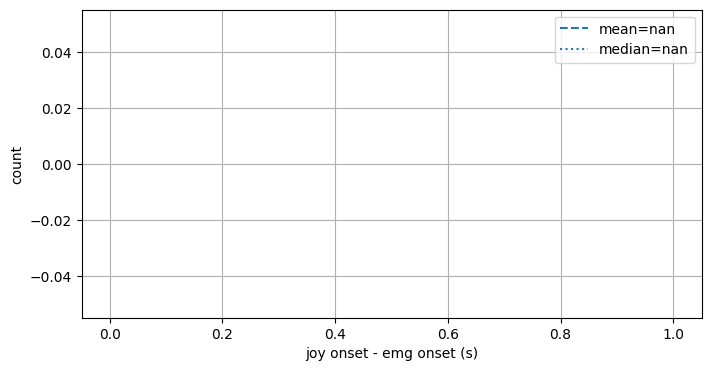

In [247]:
print("Extensor\n", summarize_onset_deltas(onsets_ext_full))
plot_delta_histogram(onsets_ext_full)

Flexor
 count               0.0
removed_outliers    2.0
outlier_low         NaN
outlier_high        NaN
mean                NaN
median              NaN
std                 NaN
min                 NaN
max                 NaN
q10                 NaN
q25                 NaN
q50                 NaN
q75                 NaN
q90                 NaN
dtype: float64


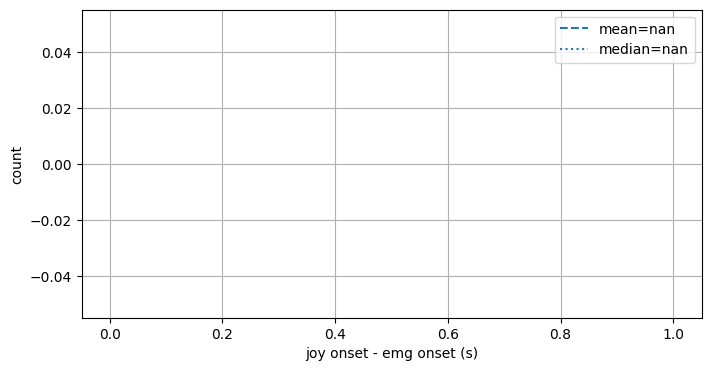

In [248]:
print("Flexor\n", summarize_onset_deltas(onsets_flex_full))
plot_delta_histogram(onsets_flex_full)

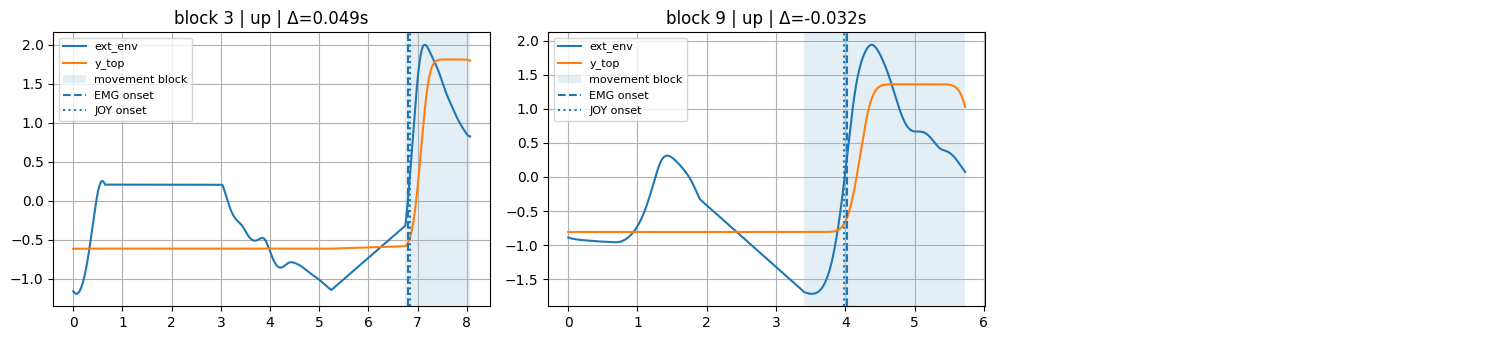

In [249]:
import numpy as np
import matplotlib.pyplot as plt
import math

def plot_onsets_blocks_with_prev_rest(
    df,
    onsets,
    emg_col,
    joy_col,
    ncols=3,
    max_blocks=18,
    normalize=True,
):
    block_ids = onsets["block_id"].dropna().astype(int).tolist()[:max_blocks]
    nrows = math.ceil(len(block_ids) / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 3.5*nrows))
    axes = np.array(axes).reshape(-1)

    for ax, block_id in zip(axes, block_ids):
        row = onsets[onsets["block_id"] == block_id].iloc[0]

        prev_rest_id = int(row["baseline_block_id"])

        g = df[df["block_id"].isin([prev_rest_id, block_id])].copy()
        if g.empty:
            ax.axis("off")
            continue

        t0 = g["t"].iloc[0]
        t = g["t"] - t0

        emg = g[emg_col].astype(float).values
        joy = g[joy_col].astype(float).values

        if normalize:
            emg = (emg - np.mean(emg)) / (np.std(emg) + 1e-9)
            joy = (joy - np.mean(joy)) / (np.std(joy) + 1e-9)

        ax.plot(t, emg, label=emg_col)
        ax.plot(t, joy, label=joy_col)

        # sombrear bloque de movimiento
        move_block = df[df["block_id"] == block_id]
        move_start = move_block["t"].iloc[0] - t0
        move_end = move_block["t"].iloc[-1] - t0
        ax.axvspan(move_start, move_end, alpha=0.12, label="movement block")

        if not np.isnan(row["t_emg_onset"]):
            ax.axvline(row["t_emg_onset"] - t0, linestyle="--", label="EMG onset")

        if not np.isnan(row["t_joy_onset"]):
            ax.axvline(row["t_joy_onset"] - t0, linestyle=":", label="JOY onset")

        delta = row.get("delta_joy_minus_emg", np.nan)
        command = row.get("command", "")
        ax.set_title(f"block {block_id} | {command} | Δ={delta:.3f}s")
        ax.grid(True)
        ax.legend(fontsize=8)

    for ax in axes[len(block_ids):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

plot_onsets_blocks_with_prev_rest(
    df,
    onsets_ext_full,
    emg_col="ext_env",
    joy_col="y_top",
    ncols=3,
    max_blocks=12,
)

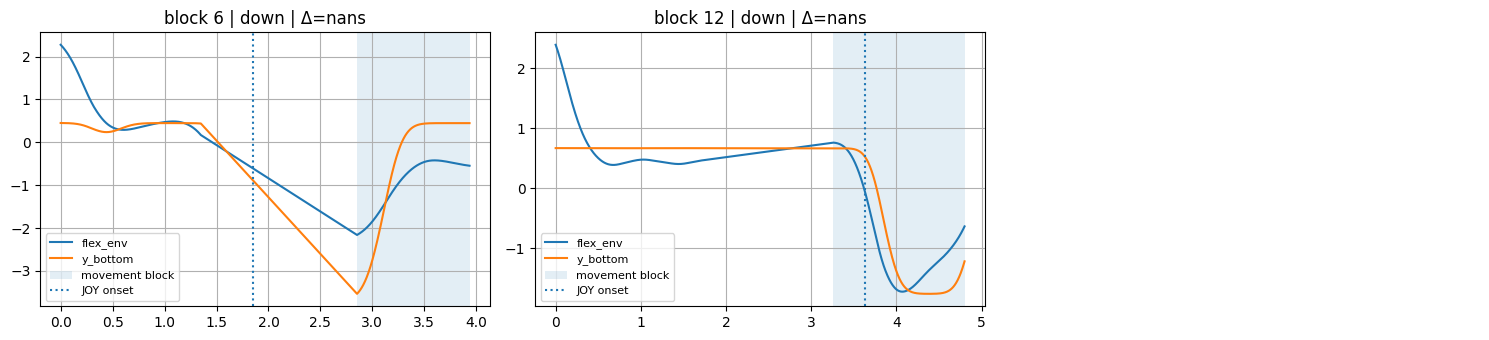

In [250]:
plot_onsets_blocks_with_prev_rest(
    df,
    onsets_flex_full,
    emg_col="flex_env",
    joy_col="y_bottom",
    ncols=3,
    max_blocks=12,
)